# TP 2 NLP -> Deep learning pour la classification de texte

Paul Pitiot, ING 3 Option IA Groupe B

## Objectif retenu

Comparer les modèles de machine learning du TP 1 (TF-IDF + modèle linéaire) à des modèles de deep learning (embedding appris, MLP, RNN, LSTM) sur la même tâche : une réplique de Tiny Shakespeare, quel personnage parle ? Étapes du sujet : 1 nettoyage et prétraitement, 2 représentation, 3 comparaison des modèles ML et DL, 4 évaluation.

`texte brut → prétraitement → représentation (TF-IDF ou embedding) → modèle ML ou DL → mesure`

Livrable : un tableau unique ML + DL sur le même test (F1 macro), les courbes train / validation, les matrices de confusion et un bilan. Le test est celui du TP 1 et rien n'est appris dessus. Les graines sont fixées ; le corpus est téléchargé et le notebook tourne en moins d'une minute sur CPU.

## 0. Environnement et config

Imports et graine fixée (`fixer_graine` : python, numpy et torch) pour retrouver les mêmes résultats à chaque exécution.

In [ ]:
%matplotlib inline

import re
import time
import copy
import io
import random
import contextlib
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42          # même graine qu'au Tp précédent


def fixer_graine(graine=RANDOM_STATE):
    # python, numpy et torch : pour que les résultats soient les mêmes d'une exécution à l'autre
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)


fixer_graine()
print(f"torch {torch.__version__}")
print("Environnement prêt.")

torch 2.1.2
Environnement prêt.


## 1. Notions reprises du TP 1

Je garde tout ce qui définit la tâche pour que les scores restent comparables : le même corpus, les 5 mêmes locuteurs (GLOUCESTER, DUKE VINCENTIO, ROMEO, PETRUCHIO, MENENIUS), le seuil de 5 mots et le même `train_test_split` (80 / 20, stratifié, `random_state = 42`). Le test est donc celui du TP 1 (153 répliques).

Ce qui change :

- Une validation est découpée dans le train, pour choisir l'époque sans regarder le test.
- Les modèles DL utilisent un `nn.Embedding` appris à la place de TF-IDF, sur des séquences qui gardent l'ordre des mots.
- Trois modèles PyTorch (MLP, RNN, LSTM) sont comparés aux trois modèles ML du TP 1.

## 2. Étape 1 : chargement et construction du dataset

Code repris du TP 1 : même parsing, 5 locuteurs, répliques d'au moins 5 mots. Je dois retrouver 761 exemples.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte). Fonction du TP1."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

N = 5        # nombre de locuteurs retenus (TP1)
SEUIL = 5    # longueur minimale d'une réplique, en mots (TP1)

top_locuteurs = df['locuteur'].value_counts().head(N).index
donnees = df[df['locuteur'].isin(top_locuteurs)].copy()
donnees = donnees[donnees['replique'].str.split().str.len() >= SEUIL]

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus (761 au TP1)")
print(f"Part de la classe majoritaire : {donnees['locuteur'].value_counts(normalize=True).max():.1%}  (plancher de l'accuracy)")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus (761 au TP1)
Part de la classe majoritaire : 25.8%  (plancher de l'accuracy)


## 3. Étape 1 : découpage train / validation / test

Le premier découpage est celui du TP 1 (même test). Le second prend 20 % du train pour la validation, stratifiée aussi. Tout ce qui apprend (vocabulaire, IDF, embeddings, poids) est ajusté sur le train seulement : la validation choisit l'époque et le test sert une seule fois, à la fin.

In [3]:
# 1) Découpage du TP1, à l'identique : le test doit être le même
X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2,
    stratify=donnees['locuteur'],
    random_state=RANDOM_STATE,
)

# 2) Nouveau : une validation découpée DANS le train
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

print(f"train TP1  : {len(X_train)} exemples (608 au TP1)")
print(f"test       : {len(X_test)} exemples (153 au TP1)")
print(f"\ntrain      : {len(X_tr)} exemples")
print(f"validation : {len(X_val)} exemples")
print(f"test       : {len(X_test)} exemples")

print("\nProportions par classe (vérification de la stratification) :")
print(pd.DataFrame({
    "train": y_tr.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3))

train TP1  : 608 exemples (608 au TP1)
test       : 153 exemples (153 au TP1)

train      : 486 exemples
validation : 122 exemples
test       : 153 exemples

Proportions par classe (vérification de la stratification) :
                train  validation   test
locuteur                                
GLOUCESTER      0.257       0.254  0.261
DUKE VINCENTIO  0.216       0.221  0.216
ROMEO           0.185       0.189  0.183
PETRUCHIO       0.175       0.172  0.176
MENENIUS        0.167       0.164  0.163


> *Commentaire - 1 :* le premier découpage redonne 608 / 153 comme au TP 1, donc le test est le même. La validation vient du train, pas du test, pour que le test reste intact. Le train passe de 608 à 486 exemples, mais ML et DL voient le même train, donc la comparaison reste juste. Les proportions par classe sont les mêmes dans les trois jeux (GLOUCESTER à 0,26).

## 4. Étape 1 : prétraitement DL (du texte aux séquences d'ids)

Un réseau lit des séquences d'entiers de longueur fixe. Je tokenise en mots minuscules, je construis le vocabulaire sur le train avec un seuil de fréquence (les mots rares deviennent `<unk>`), puis j'encode chaque réplique avec du padding `<pad>` jusqu'à `MAX_LEN` (troncature au-delà).

In [4]:
def tokeniser(txt):
    # minuscules, découpage en mots ; les apostrophes internes sont gardées (i'll, know't), la ponctuation est ignorée
    return re.findall(r"[a-z]+(?:'[a-z]+)*", txt.lower())


PAD, UNK = "<pad>", "<unk>"
MIN_FREQ = 2          # même idée que min_df=2 au TP1


def construire_vocab(textes):
    # vocabulaire construit sur le TRAIN seulement : id 0 = <pad>, id 1 = <unk>, puis les mots par fréquence
    compteur = Counter(tok for t in textes for tok in tokeniser(t))
    vocab = {PAD: 0, UNK: 1}
    for tok, n in compteur.most_common():
        if n >= MIN_FREQ:
            vocab[tok] = len(vocab)
    return vocab, compteur


vocab, compteur = construire_vocab(X_tr)
id_vers_token = {i: t for t, i in vocab.items()}

print("Exemple de tokenisation :", tokeniser(X_tr.iloc[0])[:12])
print(f"\n{len(compteur):,} tokens distincts dans le train, dont {sum(n < MIN_FREQ for n in compteur.values()):,} vus une seule fois -> {UNK}")
print(f"Vocabulaire final : {len(vocab):,} entrées ({PAD} et {UNK} compris)")
print("Les 12 plus fréquents :", [t for t, _ in compteur.most_common(12)])

Exemple de tokenisation : ['be', 'patient', 'gentlemen', 'i', 'choose', 'her', 'for', 'myself', 'if', 'she', 'and', 'i']

3,328 tokens distincts dans le train, dont 1,995 vus une seule fois -> <unk>
Vocabulaire final : 1,335 entrées (<pad> et <unk> compris)
Les 12 plus fréquents : ['the', 'and', 'to', 'i', 'you', 'of', 'a', 'that', 'my', 'in', 'is', 'me']


--- Longueur des répliques du train (en tokens) ---
count    486.0
mean      35.7
std       50.3
min        5.0
50%       18.0
75%       43.0
90%       81.0
95%      112.0
max      581.0
dtype: float64

MAX_LEN = 64 : 86.2% des répliques tiennent en entier, les autres sont coupées


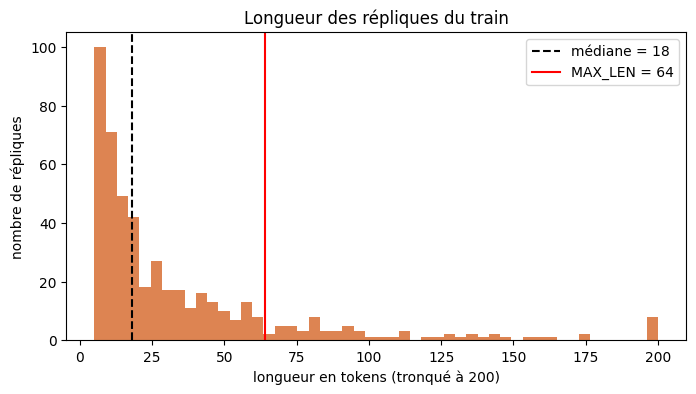

In [5]:
longueurs_train = pd.Series([len(tokeniser(t)) for t in X_tr])
print("--- Longueur des répliques du train (en tokens) ---")
print(longueurs_train.describe(percentiles=[.5, .75, .9, .95]).round(1))

MAX_LEN = 64
print(f"\nMAX_LEN = {MAX_LEN} : {(longueurs_train <= MAX_LEN).mean():.1%} des répliques tiennent en entier, "
      f"les autres sont coupées")

plt.figure(figsize=(8, 4))
plt.hist(longueurs_train.clip(upper=200), bins=50, color="#DD8452")
plt.axvline(longueurs_train.median(), color="black", ls="--", label=f"médiane = {longueurs_train.median():.0f}")
plt.axvline(MAX_LEN, color="red", label=f"MAX_LEN = {MAX_LEN}")
plt.xlabel("longueur en tokens (tronqué à 200)")
plt.ylabel("nombre de répliques")
plt.title("Longueur des répliques du train")
plt.legend()
plt.show()

In [6]:
def encoder(textes):
    # texte -> tenseur d'ids (n, MAX_LEN) : padding à droite avec 0, troncature à MAX_LEN ; on garde aussi les vraies longueurs
    ids = torch.zeros(len(textes), MAX_LEN, dtype=torch.long)
    longueurs = torch.zeros(len(textes), dtype=torch.long)
    for i, t in enumerate(textes):
        seq = [vocab.get(tok, vocab[UNK]) for tok in tokeniser(t)[:MAX_LEN]]
        ids[i, :len(seq)] = torch.tensor(seq)
        longueurs[i] = len(seq)
    return ids, longueurs


ids_tr, long_tr = encoder(X_tr)
ids_val, long_val = encoder(X_val)
ids_te, long_te = encoder(X_test)
print(f"Tenseurs : train {tuple(ids_tr.shape)} | validation {tuple(ids_val.shape)} | test {tuple(ids_te.shape)}")

for nom, ids, longueurs in [("train", ids_tr, long_tr), ("validation", ids_val, long_val), ("test", ids_te, long_te)]:
    print(f"Part de {UNK} dans le {nom:10s} : {(ids == vocab[UNK]).sum().item() / longueurs.sum().item():.1%}")

# Étiquettes : mêmes classes, dans l'ordre alphabétique comme scikit-learn
classes = sorted(y_train.unique())
classe_vers_id = {c: i for i, c in enumerate(classes)}


def encoder_labels(y):
    return torch.tensor([classe_vers_id[c] for c in y])


Y_tr, Y_val, Y_te = encoder_labels(y_tr), encoder_labels(y_val), encoder_labels(y_test)

# Un exemple, pour voir ce que le modèle reçoit vraiment
i = 3
print(f"\nRéplique de {y_val.iloc[i]} : {X_val.iloc[i][:120]}")
print("ids  :", ids_val[i, :12].tolist(), "...")
print("relu :", " ".join(id_vers_token[j] for j in ids_val[i, :12].tolist()), "...")

Tenseurs : train (486, 64) | validation (122, 64) | test (153, 64)
Part de <unk> dans le train      : 11.0%
Part de <unk> dans le validation : 17.8%
Part de <unk> dans le test       : 16.7%

Réplique de DUKE VINCENTIO : I know you'ld fain be gone. An officer! To prison with her! Shall we thus permit A blasting and a scandalous breath to f
ids  : [5, 103, 1, 1, 21, 267, 89, 976, 4, 550, 16, 22] ...
relu : i know <unk> <unk> be gone an officer to prison with her ...


> *Commentaire - 2 :*
> - Vocabulaire : le train compte 3 328 tokens distincts, dont 1 995 vus une seule fois. Avec `min_freq = 2`, il reste 1 335 entrées.
> - `<unk>` : il représente 11 % des tokens du train, 17,8 % de la validation et 16,7 % du test. TF-IDF perd les mêmes mots, car un mot absent du vocabulaire n'a pas de colonne.
> - `MAX_LEN` : la médiane est de 18 tokens, 75 % des répliques font moins de 43 tokens et la plus longue en fait 581. Avec 64, 86,2 % des répliques passent en entier.
> - Par rapport à TF-IDF, on perd les bigrammes et la pondération IDF, mais on gagne l'ordre des mots et des vecteurs denses.

## 5. Étape 2 : représentation, TF-IDF (rappel du TP 1) et `nn.Embedding`

Côté ML, le TF-IDF du TP 1 (unigrammes et bigrammes, `min_df=2`) est ré-ajusté sur le nouveau train : c'est une formule sur des comptages. Côté DL, `nn.Embedding` est une matrice « vocabulaire × `DIM_EMB` » tirée au hasard, apprise par rétropropagation avec le reste du réseau.

In [7]:
# a) TF-IDF du TP1 (mêmes paramètres), ajusté sur le train de 486 exemples
vectoriseur = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.9,
                              stop_words=None, sublinear_tf=True)
Xtr = vectoriseur.fit_transform(X_tr)      # fit + transform sur le train SEULEMENT
Xval = vectoriseur.transform(X_val)
Xte = vectoriseur.transform(X_test)
print(f"TF-IDF : {len(vectoriseur.vocabulary_):,} colonnes, "
      f"{Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.2%} de valeurs non nulles")

# b) nn.Embedding : une matrice (vocabulaire x DIM_EMB), aléatoire pour l'instant
DIM_EMB = 64
fixer_graine()
embedding_demo = nn.Embedding(len(vocab), DIM_EMB, padding_idx=0)   # la ligne 0 (<pad>) reste à zéro
print(f"Embedding : matrice {tuple(embedding_demo.weight.shape)}, "
      f"soit {embedding_demo.weight.numel():,} paramètres à apprendre sur {len(X_tr)} exemples")
print("Vecteur de 'love' avant apprentissage :", embedding_demo.weight[vocab['love'], :6].detach().numpy().round(2), "...")

# c) la même réplique vue par les deux représentations
i = 3
print(f"\nRéplique de validation n°{i} ({int(long_val[i])} tokens) :")
print(f"  TF-IDF    : un vecteur de {Xval.shape[1]:,} cases, {Xval[i].nnz} non nulles")
print(f"  Embedding : un tenseur {tuple(embedding_demo(ids_val[i:i + 1]).shape)}, un vecteur dense de {DIM_EMB} valeurs par token")

TF-IDF : 2,803 colonnes, 1.17% de valeurs non nulles
Embedding : matrice (1335, 64), soit 85,440 paramètres à apprendre sur 486 exemples
Vecteur de 'love' avant apprentissage : [ 0.77  0.02  0.68 -0.13  0.1   0.8 ] ...

Réplique de validation n°3 (43 tokens) :
  TF-IDF    : un vecteur de 2,803 cases, 39 non nulles
  Embedding : un tenseur (1, 64, 64), un vecteur dense de 64 valeurs par token


> *Commentaire - 3 :*
> - Dense contre creux : une réplique de 43 tokens donne un vecteur de 2 803 cases dont 39 non nulles en TF-IDF (1,17 % de valeurs non nulles sur la matrice train), contre un tenseur 64 × 64 entièrement rempli avec l'embedding.
> - Appris contre calculé : TF-IDF vient d'une formule et n'a rien à entraîner, alors que le vecteur de « love » affiché est un tirage aléatoire qui ne devient utile que si le gradient le pousse.
> - Un seul vecteur par mot : « love » nom ou verbe a la même ligne, comme avec TF-IDF.
> - Paramètres contre exemples : l'embedding compte 1 335 × 64 = 85 440 paramètres pour 486 exemples, alors que TF-IDF + régression logistique n'a que 14 020 coefficients. J'attends du sur-apprentissage.

## 6. Étape 3 : référence ML, les modèles du TP 1

D'abord un contrôle : les modèles du TP 1, entraînés sur le train du TP 1 (608 exemples), doivent redonner ses scores. Ensuite les baselines et les trois modèles ML sont ré-entraînés sur le nouveau train (486 exemples), comme les modèles DL.

In [8]:
def modeles_ml():
    # les trois modèles du TP1, mêmes hyperparamètres
    return {
        "LogisticRegression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
        "LinearSVC": LinearSVC(class_weight='balanced', random_state=RANDOM_STATE),
        "MultinomialNB": MultinomialNB(),
    }


# Contrôle : train du TP1 (608 exemples) -> je dois retrouver 0,668 / 0,649 / 0,535
vec_tp1 = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.9, stop_words=None, sublinear_tf=True)
A, B = vec_tp1.fit_transform(X_train), vec_tp1.transform(X_test)
print("--- Contrôle : train du TP1 (608 exemples) ---")
for nom, modele in modeles_ml().items():
    print(f"{nom:20s} F1 macro test = {f1_score(y_test, modele.fit(A, y_train).predict(B), average='macro'):.3f}")

# Référence pour la comparaison : nouveau train (486 exemples)
resultats = {}     # nom -> prédictions sur le test
infos = {}         # nom -> (famille, nombre de paramètres, temps d'entraînement en s)

print("\n--- Baselines ---")
for nom, strategie in [("Baseline (classe majoritaire)", "most_frequent"), ("Baseline (aléatoire stratifié)", "stratified")]:
    dummy = DummyClassifier(strategy=strategie, random_state=RANDOM_STATE).fit(Xtr, y_tr)
    resultats[nom] = dummy.predict(Xte)
    infos[nom] = ("baseline", 0, 0.0)
    print(f"{nom:32s} accuracy = {accuracy_score(y_test, resultats[nom]):.3f} | F1 macro = {f1_score(y_test, resultats[nom], average='macro'):.3f}")

print("\n--- Modèles ML (train = 486 exemples) ---")
modeles_ml_entraines = {}
for nom, modele in modeles_ml().items():
    debut = time.time()
    modele.fit(Xtr, y_tr)
    duree = time.time() - debut
    n_params = modele.coef_.size + modele.intercept_.size if hasattr(modele, "coef_") else modele.feature_log_prob_.size
    modeles_ml_entraines[nom] = modele
    resultats[nom] = modele.predict(Xte)
    infos[nom] = ("ML", n_params, duree)
    print(f"{nom:20s} F1 macro validation = {f1_score(y_val, modele.predict(Xval), average='macro'):.3f} | "
          f"F1 macro test = {f1_score(y_test, resultats[nom], average='macro'):.3f} | "
          f"{duree * 1000:4.0f} ms | {n_params:,} paramètres")

--- Contrôle : train du TP1 (608 exemples) ---
LogisticRegression   F1 macro test = 0.668
LinearSVC            F1 macro test = 0.649
MultinomialNB        F1 macro test = 0.535

--- Baselines ---
Baseline (classe majoritaire)    accuracy = 0.261 | F1 macro = 0.083
Baseline (aléatoire stratifié)   accuracy = 0.216 | F1 macro = 0.215

--- Modèles ML (train = 486 exemples) ---


LogisticRegression   F1 macro validation = 0.590 | F1 macro test = 0.616 |   39 ms | 14,020 paramètres
LinearSVC            F1 macro validation = 0.606 | F1 macro test = 0.593 |   12 ms | 14,020 paramètres
MultinomialNB        F1 macro validation = 0.488 | F1 macro test = 0.506 |    2 ms | 14,015 paramètres


> *Commentaire - 4 :*
> - Le contrôle redonne exactement 0,668 / 0,649 / 0,535, les scores du TP 1 : le protocole est bien le même.
> - Sur le train de 486 exemples, les scores baissent : 0,616 pour LogisticRegression, 0,593 pour LinearSVC et 0,506 pour MultinomialNB, ce qui est cohérent avec 20 % de train en moins.
> - Les baselines ne changent pas (accuracy 0,261, F1 macro 0,083) : le plancher est celui du TP 1.

## 7. Étape 3 : modèles DL

Trois architectures, chacune dans une classe PyTorch. Toutes commencent par `nn.Embedding` et finissent par une couche linéaire vers les 5 classes.

| Modèle | Ce qu'il fait des vecteurs de mots | Ordre des mots ? |
|---|---|---|
| **MLP** (sac d'embeddings) | moyenne des vecteurs de la réplique, puis une couche cachée | non |
| **RNN** simple (`nn.RNN`) | lit les mots un par un, le dernier état caché résume la réplique | oui |
| **LSTM** (`nn.LSTM`) | pareil, avec des portes de mémoire (cours) | oui |

La boucle est la même pour les trois : `CrossEntropyLoss` pondérée par classe (comme `class_weight='balanced'` au TP 1), `Adam`, mini-batchs de 32, 30 époques. On garde les poids de l'époque au meilleur F1 macro de validation (early stopping).

In [9]:
DIM_CACHE = 64     # taille de l'état caché des RNN / de la couche cachée du MLP
DROPOUT = 0.3
LR = 5e-3
BATCH = 32
EPOCHS = 30


class MLP(nn.Module):
    # Sac d'embeddings : moyenne des vecteurs des mots (l'ordre est perdu), puis deux couches

    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), DIM_EMB, padding_idx=0)
        self.fc1 = nn.Linear(DIM_EMB, DIM_CACHE)
        self.fc2 = nn.Linear(DIM_CACHE, len(classes))
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, ids, longueurs):
        e = self.emb(ids)                                  # (batch, MAX_LEN, DIM_EMB), les <pad> valent 0
        moyenne = e.sum(1) / longueurs.unsqueeze(1)        # moyenne sur les vrais mots seulement
        h = torch.relu(self.fc1(self.drop(moyenne)))
        return self.fc2(self.drop(h))


class RNN(nn.Module):
    # RNN simple : lit les mots un par un, l'état caché au dernier mot résume la réplique

    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), DIM_EMB, padding_idx=0)
        self.rnn = nn.RNN(DIM_EMB, DIM_CACHE, batch_first=True)
        self.fc = nn.Linear(DIM_CACHE, len(classes))
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, ids, longueurs):
        sorties, _ = self.rnn(self.drop(self.emb(ids)))            # un état caché par position
        dernier = sorties[torch.arange(len(ids)), longueurs - 1]   # l'état au dernier vrai mot, pas après les <pad>
        return self.fc(self.drop(dernier))


class LSTM(nn.Module):
    # Même chose avec une cellule LSTM (portes d'oubli, d'écriture, de sortie)

    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), DIM_EMB, padding_idx=0)
        self.lstm = nn.LSTM(DIM_EMB, DIM_CACHE, batch_first=True)
        self.fc = nn.Linear(DIM_CACHE, len(classes))
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, ids, longueurs):
        sorties, _ = self.lstm(self.drop(self.emb(ids)))
        dernier = sorties[torch.arange(len(ids)), longueurs - 1]
        return self.fc(self.drop(dernier))

In [10]:
# Loss pondérée par classe : poids = n / (K * n_k), c'est la formule de class_weight='balanced'
comptes = np.bincount(Y_tr.numpy())
poids_classes = torch.tensor(len(Y_tr) / (len(classes) * comptes), dtype=torch.float32)
critere = nn.CrossEntropyLoss(weight=poids_classes)
print("Poids de classe :", dict(zip(classes, poids_classes.numpy().round(2))))


def predire(modele, ids, longueurs):
    # prédictions (ids de classe) sur un jeu entier, en mode évaluation (pas de dropout)
    modele.eval()
    with torch.no_grad():
        return modele(ids, longueurs).argmax(1).numpy()


def f1_macro(Y, pred):
    return f1_score(Y.numpy(), pred, average="macro")


def entrainer(modele):
    # Adam + mini-batchs mélangés, EPOCHS époques. A chaque époque : loss train, F1 train et F1 validation.
    # On garde une copie des poids de l'époque où le F1 validation est le meilleur (early stopping).
    optimiseur = torch.optim.Adam(modele.parameters(), lr=LR)
    historique = {"loss_train": [], "f1_train": [], "f1_val": []}
    meilleur_f1, meilleur_etat, meilleure_epoque = -1, None, 0
    debut = time.time()

    for epoque in range(1, EPOCHS + 1):
        modele.train()
        pertes = []
        for idx in torch.randperm(len(ids_tr)).split(BATCH):
            optimiseur.zero_grad()
            perte = critere(modele(ids_tr[idx], long_tr[idx]), Y_tr[idx])
            perte.backward()
            optimiseur.step()
            pertes.append(perte.item())

        f1_tr = f1_macro(Y_tr, predire(modele, ids_tr, long_tr))
        f1_va = f1_macro(Y_val, predire(modele, ids_val, long_val))
        historique["loss_train"].append(np.mean(pertes))
        historique["f1_train"].append(f1_tr)
        historique["f1_val"].append(f1_va)
        if f1_va > meilleur_f1:
            meilleur_f1, meilleure_epoque = f1_va, epoque
            meilleur_etat = copy.deepcopy(modele.state_dict())
        if epoque % 5 == 0:
            print(f"    époque {epoque:2d} | loss train {np.mean(pertes):.3f} | F1 train {f1_tr:.3f} | F1 validation {f1_va:.3f}")

    modele.load_state_dict(meilleur_etat)
    return historique, meilleure_epoque, time.time() - debut

Poids de classe : {'DUKE VINCENTIO': 0.93, 'GLOUCESTER': 0.78, 'MENENIUS': 1.2, 'PETRUCHIO': 1.14, 'ROMEO': 1.08}


In [11]:
modeles_dl, historiques, epoques = {}, {}, {}

for nom, Classe in [("MLP", MLP), ("RNN", RNN), ("LSTM", LSTM)]:
    fixer_graine()                     # chaque modèle part de la même graine
    modele = Classe()
    n_params = sum(p.numel() for p in modele.parameters())
    print(f"=== {nom} : {n_params:,} paramètres ===")
    historique, meilleure_epoque, duree = entrainer(modele)
    pred = predire(modele, ids_te, long_te)
    print(f"    -> poids de l'époque {meilleure_epoque} gardés | F1 validation = {historique['f1_val'][meilleure_epoque - 1]:.3f} "
          f"| F1 test = {f1_macro(Y_te, pred):.3f} | {duree:.1f} s\n")
    modeles_dl[nom], historiques[nom], epoques[nom] = modele, historique, meilleure_epoque
    resultats[nom] = np.array(classes)[pred]
    infos[nom] = ("DL", n_params, duree)

=== MLP : 89,925 paramètres ===


    époque  5 | loss train 1.300 | F1 train 0.635 | F1 validation 0.343
    époque 10 | loss train 0.692 | F1 train 0.899 | F1 validation 0.483
    époque 15 | loss train 0.363 | F1 train 0.977 | F1 validation 0.466
    époque 20 | loss train 0.179 | F1 train 0.996 | F1 validation 0.538


    époque 25 | loss train 0.137 | F1 train 0.996 | F1 validation 0.504
    époque 30 | loss train 0.083 | F1 train 0.998 | F1 validation 0.527
    -> poids de l'époque 27 gardés | F1 validation = 0.538 | F1 test = 0.584 | 0.4 s

=== RNN : 94,085 paramètres ===


    époque  5 | loss train 1.177 | F1 train 0.719 | F1 validation 0.207


    époque 10 | loss train 0.729 | F1 train 0.908 | F1 validation 0.206


...

    époque 10 | loss train 0.405 | F1 train 0.972 | F1 validation 0.369


    époque 15 | loss train 0.192 | F1 train 0.998 | F1 validation 0.369


    époque 20 | loss train 0.126 | F1 train 1.000 | F1 validation 0.401


    époque 25 | loss train 0.085 | F1 train 1.000 | F1 validation 0.424


    époque 30 | loss train 0.084 | F1 train 1.000 | F1 validation 0.348
    -> poids de l'époque 14 gardés | F1 validation = 0.427 | F1 test = 0.392 | 5.4 s



> *Commentaire - 5 :*
> - La loss est pondérée parce que la métrique est le F1 macro, qui compte chaque locuteur à égalité (poids de 0,78 pour GLOUCESTER à 1,2 pour MENENIUS).
> - Le MLP apprend vite : F1 train de 0,90 dès l'époque 10 et validation jusqu'à 0,538 à l'époque 27.
> - Le RNN mémorise sans généraliser : validation de 0,263 au mieux (époque 8) et train à 1,000 à l'époque 30.
> - Le LSTM fait mieux (0,427 à l'époque 14) mais oscille beaucoup, d'où l'intérêt de garder la meilleure époque.
> - Les trois finissent avec un F1 train proche de 1,0 : ils ont la capacité de mémoriser 486 exemples.

## 8. Étape 4 : évaluer et comparer

### 8.1 Le tableau unique ML + DL

Même test et mêmes métriques qu'au TP 1, plus le nombre de paramètres et le temps d'entraînement.

In [12]:
lignes = []
for nom, pred in resultats.items():
    fam, n_params, duree = infos[nom]
    lignes.append({
        "modèle": nom,
        "famille": fam,
        "accuracy": accuracy_score(y_test, pred),
        "précision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel (macro)": recall_score(y_test, pred, average="macro"),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "F1 weighted": f1_score(y_test, pred, average="weighted"),
        "paramètres": n_params,
        "temps (s)": duree,
    })

tableau = pd.DataFrame(lignes).set_index("modèle")
display(tableau.round(3))

,famille,accuracy,précision (macro),rappel (macro),F1 macro,F1 weighted,paramètres,temps (s)
modèle,,,,,,,,
Baseline (classe majoritaire),baseline,0.261,0.052,0.200,0.083,0.108,0,0.000
Baseline (aléatoire stratifié),baseline,0.216,0.218,0.216,0.215,0.216,0,0.000
LogisticRegression,ML,0.614,0.623,0.617,0.616,0.616,14020,0.039
LinearSVC,ML,0.595,0.602,0.594,0.593,0.597,14020,0.012
MultinomialNB,ML,0.542,0.773,0.497,0.506,0.517,14015,0.002
MLP,DL,0.582,0.594,0.587,0.584,0.584,89925,0.352
RNN,DL,0.275,0.273,0.280,0.273,0.270,94085,2.145
LSTM,DL,0.386,0.398,0.393,0.392,0.385,119045,5.401


> *Commentaire - 6 :*
> - Le meilleur modèle est LogisticRegression sur TF-IDF (0,616 de F1 macro), devant LinearSVC (0,593), le MLP (0,584, le meilleur DL), MultinomialNB (0,506), le LSTM (0,392) et le RNN (0,273), à peine au-dessus de la baseline aléatoire stratifiée (0,215).
> - Les modèles ML ont 14 020 paramètres et s'entraînent en quelques millisecondes. Les modèles DL ont de 90 000 à 119 000 paramètres et mettent de 0,4 à 5,4 s, pour un score inférieur.

### 8.2 Courbes train / validation

F1 macro sur le train et la validation à chaque époque, pour chaque modèle DL. La ligne pointillée marque l'époque dont les poids sont gardés.

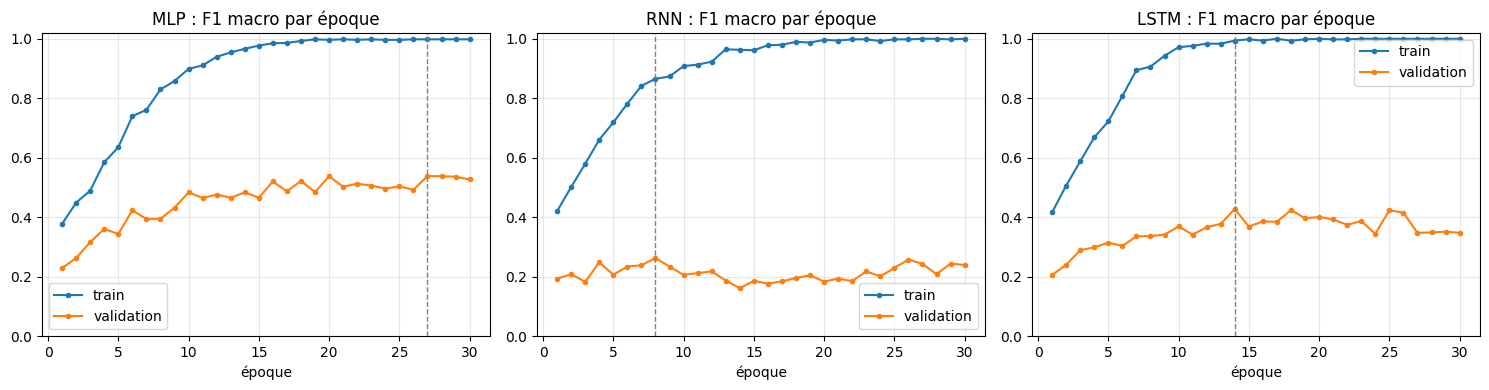

A l'époque retenue :
  MLP   époque 27 : F1 train = 0.998 | F1 validation = 0.538 | écart = 0.460
  RNN   époque  8 : F1 train = 0.865 | F1 validation = 0.263 | écart = 0.603
  LSTM  époque 14 : F1 train = 0.994 | F1 validation = 0.427 | écart = 0.567


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nom in zip(axes, modeles_dl):
    h = historiques[nom]
    ax.plot(range(1, EPOCHS + 1), h["f1_train"], marker=".", label="train")
    ax.plot(range(1, EPOCHS + 1), h["f1_val"], marker=".", label="validation")
    ax.axvline(epoques[nom], color="gray", ls="--", lw=1)
    ax.set_title(f"{nom} : F1 macro par époque")
    ax.set_xlabel("époque")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

print("A l'époque retenue :")
for nom in modeles_dl:
    e = epoques[nom] - 1
    h = historiques[nom]
    print(f"  {nom:5s} époque {e + 1:2d} : F1 train = {h['f1_train'][e]:.3f} | F1 validation = {h['f1_val'][e]:.3f} "
          f"| écart = {h['f1_train'][e] - h['f1_val'][e]:.3f}")

> *Commentaire - 7 :*
> - MLP : le train atteint 0,998 et la validation finit à 0,538, soit un écart de 0,46 à l'époque retenue.
> - RNN : le train finit à 1,0 mais la validation reste entre 0,17 et 0,26, soit un écart de 0,60.
> - LSTM : le train est à 0,99 dès l'époque 12 et la validation monte jusqu'à 0,427 (époque 14) puis oscille entre 0,35 et 0,42, soit un écart de 0,57.
>
> Les trois réseaux apprennent le train mais généralisent mal : 486 exemples pour 90 000 à 119 000 paramètres, et un dropout de 0,3 ne suffit pas. La variabilité selon la graine est mesurée en 8.4.

### 8.3 Matrices de confusion : meilleur ML contre meilleur DL

Côte à côte sur le même test, pour voir si les deux modèles se trompent sur les mêmes répliques.

Meilleur ML : LogisticRegression | meilleur DL : MLP


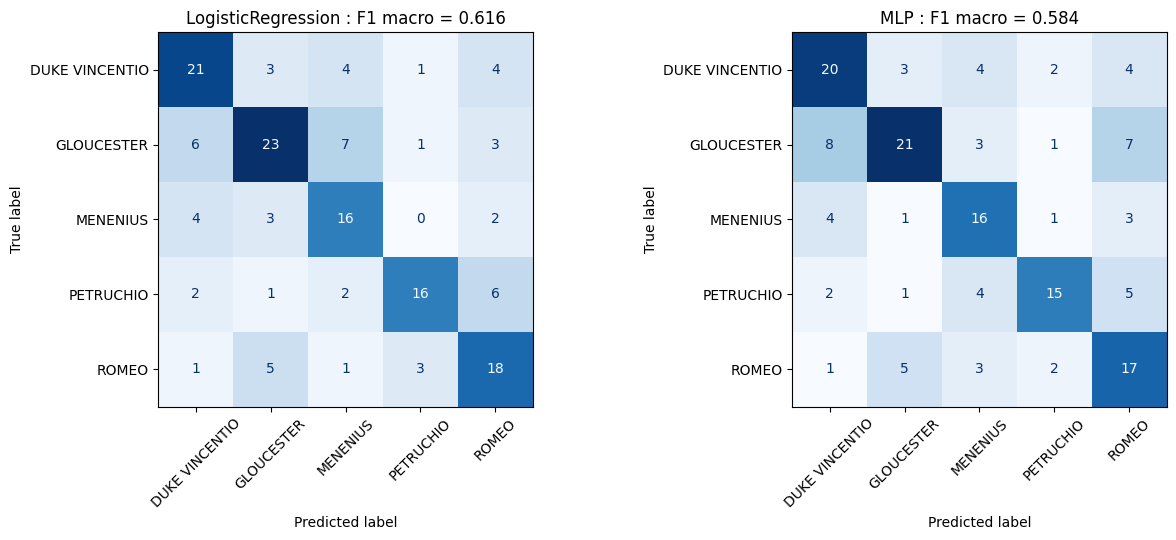

In [14]:
sans_baseline = tableau[tableau["famille"] != "baseline"]
ML_RETENU = sans_baseline[sans_baseline["famille"] == "ML"]["F1 macro"].idxmax()
DL_RETENU = sans_baseline[sans_baseline["famille"] == "DL"]["F1 macro"].idxmax()
print(f"Meilleur ML : {ML_RETENU} | meilleur DL : {DL_RETENU}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, nom in zip(axes, (ML_RETENU, DL_RETENU)):
    ConfusionMatrixDisplay.from_predictions(
        y_test, resultats[nom], labels=classes,
        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{nom} : F1 macro = {tableau.loc[nom, 'F1 macro']:.3f}")
plt.tight_layout()
plt.show()

In [15]:
print(f"--- {DL_RETENU} : rapport par locuteur ---")
print(classification_report(y_test, resultats[DL_RETENU], digits=3))

# Les deux modèles se trompent-ils sur les mêmes répliques ?
err_ml = resultats[ML_RETENU] != y_test.values
err_dl = resultats[DL_RETENU] != y_test.values
print(f"Erreurs {ML_RETENU} : {err_ml.sum()} | erreurs {DL_RETENU} : {err_dl.sum()} | en commun : {(err_ml & err_dl).sum()} (sur {len(y_test)})")

print("\nCinq répliques ratées par les deux modèles :")
communes = err_ml & err_dl
for texte_err, vrai, p_ml, p_dl in list(zip(X_test[communes], y_test[communes],
                                            resultats[ML_RETENU][communes], resultats[DL_RETENU][communes]))[:5]:
    print(f"\nvrai = {vrai} | {ML_RETENU} = {p_ml} | {DL_RETENU} = {p_dl}")
    print(f'  "{texte_err[:150]}"')

--- MLP : rapport par locuteur ---
                precision    recall  f1-score   support

DUKE VINCENTIO      0.571     0.606     0.588        33
    GLOUCESTER      0.677     0.525     0.592        40
      MENENIUS      0.533     0.640     0.582        25
     PETRUCHIO      0.714     0.556     0.625        27
         ROMEO      0.472     0.607     0.531        28

      accuracy                          0.582       153
     macro avg      0.594     0.587     0.584       153
  weighted avg      0.600     0.582     0.584       153

Erreurs LogisticRegression : 59 | erreurs MLP : 64 | en commun : 52 (sur 153)

Cinq répliques ratées par les deux modèles :

vrai = ROMEO | LogisticRegression = GLOUCESTER | MLP = MENENIUS
  "Switch and spurs, switch and spurs; or I'll cry a match."

vrai = PETRUCHIO | LogisticRegression = ROMEO | MLP = ROMEO
  "Why, thou say'st true; it is a paltry cap, A custard-coffin, a bauble, a silken pie: I love thee well, in that thou likest it not."

vrai = PETR

> *Commentaire - 8 :*
> - Les erreurs sont en grande partie les mêmes : LogisticRegression fait 59 erreurs, le MLP 64, dont 52 en commun. Ce sont les formules courtes et génériques déjà vues au TP 1, difficiles à attribuer même pour un humain.
> - La régression logistique étale ses confusions. Le MLP confond surtout GLOUCESTER avec DUKE VINCENTIO (8) et ROMEO (7), reconnaît le mieux PETRUCHIO (F1 0,625) et le moins bien ROMEO (0,531).
> - Le vocabulaire DL n'est pas plus pauvre que TF-IDF : les noms propres du TP 1 y sont. Je pense que le MLP apprend le même raccourci qu'au TP 1, repérer la pièce, mais moins bien ; je ne l'ai pas vérifié.

### 8.4 Variabilité selon la graine

Chaque réseau a été entraîné une fois (graine 42). Pour juger les écarts du tableau 8.1, je ré-entraîne les trois réseaux avec 4 autres graines (mêmes données, même config). Les modèles ML sont déterministes. Je compare aussi les erreurs du meilleur ML et du meilleur DL avec un test de McNemar exact.

In [ ]:
GRAINES = [42, 1, 2, 3, 4]
f1_graines = {nom: [tableau.loc[nom, "F1 macro"]] for nom in modeles_dl}      # graine 42 : déjà entraînée plus haut

for graine in GRAINES[1:]:
    for nom, Classe in [("MLP", MLP), ("RNN", RNN), ("LSTM", LSTM)]:
        fixer_graine(graine)
        modele = Classe()
        with contextlib.redirect_stdout(io.StringIO()):       # on n'affiche pas à nouveau les époques
            entrainer(modele)
        f1_graines[nom].append(f1_macro(Y_te, predire(modele, ids_te, long_te)))

valeurs = pd.DataFrame(f1_graines, index=[f"graine {g}" for g in GRAINES]).T
valeurs["moyenne"] = valeurs[[f"graine {g}" for g in GRAINES]].mean(axis=1)
valeurs["écart-type"] = valeurs[[f"graine {g}" for g in GRAINES]].std(axis=1)
print("F1 macro sur le test, selon la graine :")
print(valeurs.round(3).to_string())
print(f"\nRéférence ML (déterministe) : {ML_RETENU} = {tableau.loc[ML_RETENU, 'F1 macro']:.3f}")

# McNemar exact : meilleur ML contre meilleur DL (graine 42), sur les 153 répliques du test
juste_ml = resultats[ML_RETENU] == y_test.values
juste_dl = resultats[DL_RETENU] == y_test.values
ml_seul, dl_seul = int((juste_ml & ~juste_dl).sum()), int((~juste_ml & juste_dl).sum())
p = binomtest(ml_seul, ml_seul + dl_seul, 0.5).pvalue
print(f"\n{ML_RETENU} juste et {DL_RETENU} faux : {ml_seul} | l'inverse : {dl_seul} | McNemar exact p = {p:.2f}")

F1 macro sur le test, selon la graine :
      graine 42  graine 1  graine 2  graine 3  graine 4  moyenne  écart-type
MLP       0.584     0.547     0.591     0.560     0.527    0.562       0.026
RNN       0.273     0.282     0.323     0.313     0.206    0.279       0.046
LSTM      0.392     0.393     0.448     0.336     0.398    0.393       0.040

Référence ML (déterministe) : LogisticRegression = 0.616

LogisticRegression juste et MLP faux : 12 | l'inverse : 7 | McNemar exact p = 0.36


> *Commentaire - 9 :*
> - Variabilité : le F1 macro du test va de 0,527 à 0,591 pour le MLP (0,562 ± 0,026), de 0,206 à 0,323 pour le RNN (0,279 ± 0,046) et de 0,336 à 0,448 pour le LSTM (0,393 ± 0,040).
> - Ce qui tient : l'ordre MLP > LSTM > RNN, car le pire MLP (0,527) est au-dessus du meilleur LSTM (0,448).
> - Ce qui ne tient pas : aucune graine du MLP n'atteint LogisticRegression (0,616), mais le test ne compte que 153 répliques. À la graine 42, LogisticRegression a juste là où le MLP se trompe 12 fois, et l'inverse 7 fois (McNemar exact, p = 0,36) : cet écart est dans le bruit.
> - Le DL ne fait donc pas mieux que le linéaire ici, mais je ne peux pas dire que le linéaire est meilleur.

### 8.5 Bilan : pourquoi le ML linéaire tient tête au DL ici

> *Mon constat :*
> - Le problème est petit et lexical : 486 répliques de 18 tokens en médiane, et un signal qui tient à la présence de mots (noms propres, registre). TF-IDF donne gratuitement ce que le DL doit apprendre, et LogisticRegression n'a que 14 020 paramètres contre 89 925 pour le MLP.
> - Le DL apprend le train par cœur (F1 train de 1,0 pour les trois) et le même signal lexical qu'au TP 1 (52 erreurs communes sur 64). Les modèles récurrents, censés apporter l'ordre des mots, font moins bien que le MLP qui l'ignore (vérifié en partie 9).
> - Le DL coûte plus cher (0,4 à 5,4 s contre quelques millisecondes, 6 ou 7 choix à justifier, un résultat qui dépend de la graine) sans gain mesuré. Le MLP est 3 points sous le meilleur ML à la graine 42 et 5 points sous en moyenne (8.4), mais l'écart n'est pas significatif (McNemar, p = 0,36).
> - Limite : seule l'époque est choisie sur la validation pour le DL, alors que le TF-IDF a été réglé sur le test au TP 1. Mon hypothèse est que le DL n'aurait d'intérêt qu'avec plus de données ou des embeddings pré-entraînés, mais je ne l'ai pas testé.

## 9. Test en plus : l'ordre des mots compte-t-il ?

J'évalue les trois modèles sur le test avec les mots de chaque réplique mélangés au hasard (3 mélanges, sans ré-entraînement), et le modèle ML aussi, dont le TF-IDF contient des bigrammes.

In [16]:
def melanger_ids(ids, longueurs, rng):
    # permute les mots de chaque réplique, le padding reste à droite
    melange = ids.clone()
    for i, n in enumerate(longueurs.tolist()):
        melange[i, :n] = ids[i, :n][torch.as_tensor(rng.permutation(n))]
    return melange


lignes = []
for nom in modeles_dl:
    f1s = []
    for k in range(3):
        rng = np.random.default_rng(RANDOM_STATE + k)
        f1s.append(f1_macro(Y_te, predire(modeles_dl[nom], melanger_ids(ids_te, long_te, rng), long_te)))
    lignes.append({"modèle": nom, "F1 ordre normal": tableau.loc[nom, "F1 macro"],
                   "F1 mots mélangés (moyenne)": np.mean(f1s), "min": min(f1s), "max": max(f1s)})

f1s = []
for k in range(3):
    rng = np.random.default_rng(RANDOM_STATE + k)
    X_melange = [" ".join(rng.permutation(t.split())) for t in X_test]
    f1s.append(f1_score(y_test, modeles_ml_entraines[ML_RETENU].predict(vectoriseur.transform(X_melange)), average="macro"))
lignes.append({"modèle": ML_RETENU + " (TF-IDF)", "F1 ordre normal": tableau.loc[ML_RETENU, "F1 macro"],
               "F1 mots mélangés (moyenne)": np.mean(f1s), "min": min(f1s), "max": max(f1s)})

print(pd.DataFrame(lignes).set_index("modèle").round(3).to_string())

                             F1 ordre normal  F1 mots mélangés (moyenne)    min    max
modèle                                                                                
MLP                                    0.584                       0.584  0.584  0.584
RNN                                    0.273                       0.251  0.212  0.281
LSTM                                   0.392                       0.400  0.383  0.426
LogisticRegression (TF-IDF)            0.616                       0.573  0.566  0.577


> *Commentaire - 10 :*
> - Le MLP ne bouge pas (0,584 dans les deux cas), ce qui est normal puisqu'il moyenne les vecteurs.
> - Le LSTM passe de 0,392 à 0,400 en moyenne et le RNN de 0,273 à 0,251 : l'écart est du même ordre que la différence entre deux mélanges, donc je ne vois pas de chute nette. Les modèles récurrents se comportent comme des sacs de mots.
> - LogisticRegression est le seul qui perd quelque chose (0,616 à 0,573), car ses bigrammes captent un peu d'ordre local. Avec 3 mélanges sur 153 répliques, je reste prudent.

## 10. Pour aller plus loin

Trois pistes que je n'ai pas testées :

- Les sous-mots (BPE, WordPiece) supprimeraient les mots inconnus : environ un token sur six est `<unk>` sur le test.
- Une attention sur les états du LSTM pondérerait tous les états au lieu du seul dernier.
- Un encodeur pré-entraîné (BERT) partirait d'embeddings appris sur de très gros corpus.

## 11. Consignes du sujet

| Consigne | Où |
|---|---|
| Nettoyage et prétraitement | parties 2 à 4 |
| Représentation (TF-IDF, embedding appris) | parties 4 et 5 |
| Comparaison de modèles ML et DL | parties 6 et 7, tableau en 8.1 |
| Évaluation (accuracy, précision, rappel, F1, matrices de confusion) | partie 8 |
| Pas de fuite vers le test, graines fixées, variabilité | parties 3 et 8.4 |
| Test en plus : l'ordre des mots | partie 9 |